# NFL con ojos de casa de apuestas: EDA para modelar

Un trader de una casa de apuestas no empieza preguntando quién va a ganar. Empieza con tres preguntas:

1. **¿Qué tan bueno es el mercado?** La línea de cierre es el mejor modelo público que existe. Cualquier modelo propio se mide contra ella, no contra el porcentaje de aciertos.
2. **¿Qué forma tienen los resultados?** En la NFL los márgenes caen en números fijos (3, 7, 10) por la forma de anotar. Esa forma decide cuánto vale medio punto y cómo se preparan teasers y líneas alternativas.
3. **¿Qué señales son reales?** Muchas estadísticas parecen predictivas y son ruido. Separar señal de ruido define las variables del modelo.

Este notebook responde esas tres preguntas con datos reales y termina con los insights y el plan de modelado.

**Para correrlo:** `pip install pandas numpy matplotlib scipy statsmodels pyarrow`. Todo se descarga solo la primera vez y queda guardado en una carpeta local.

**Datos**
* **nflverse `games.csv`:** todos los partidos desde 1999 con spread, total y moneyline de cierre, clima, descanso y entrenadores. Trae el ID de ESPN de cada partido, así que se cruza directo con los notebooks de la API de ESPN.
* **nflverse play by play 2016 a 2025:** cada jugada con EPA (puntos esperados agregados) y success rate. Son unos 200 MB; la primera corrida los descarga y después quedan en `data_nfl/`.

**Convenciones**
* `spread_line` es el margen esperado del local: +3 significa local favorito por 3.
* `result` es puntos del local menos puntos del visitante. El local cubre si `result > spread_line`.
* Una apuesta a -110 necesita acertar 52.4% para no perder dinero.

In [1]:
import warnings
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA = Path("data_nfl")
DATA.mkdir(exist_ok=True)
GAMES_URL = "https://raw.githubusercontent.com/nflverse/nfldata/master/data/games.csv"
PBP_URL = "https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_{}.parquet"
PBP_SEASONS = range(2016, 2026)

# Paleta validada para daltonismo y estilo sobrio
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "violet": "#6250d6", "red": "#e34948", "ink": "#0b0b0b", "ink2": "#52514e",
     "muted": "#898781", "grid": "#e1e0d9", "base": "#c3c2b7", "surface": "#fcfcfb"}
mpl.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["base"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 9.5,
})


def fetch(url, path):
    """Descarga una sola vez y reutiliza el archivo local."""
    path = Path(path)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path


def wilson(k, n, z=1.96):
    """Intervalo de confianza de Wilson para una proporción."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z**2 / n
    mid = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return mid - half, mid + half


def ml_to_prob(ml):
    """Moneyline americano a probabilidad implícita (todavía con el margen de la casa)."""
    ml = np.asarray(ml, float)
    return np.where(ml < 0, -ml / (-ml + 100), 100 / (ml + 100))


def american_to_decimal(ml):
    ml = np.asarray(ml, float)
    return np.where(ml < 0, 1 + 100 / -ml, 1 + ml / 100)


def decimal_to_american(d):
    d = np.asarray(d, float)
    return np.where(d >= 2, (d - 1) * 100, -100 / (d - 1))


BREAKEVEN_110 = 110 / 210
print(f"Break even a -110: {BREAKEVEN_110:.2%}")

Break even a -110: 52.38%


## 1. Datos y control de calidad

Antes de cualquier análisis hay que saber qué tan completa está la data. Para un modelador de apuestas importan cuatro cosas: que cada partido tenga línea de cierre, cuántos partidos se jugaron en sede neutral (ahí no hay ventaja de local), cuántos terminaron exactamente en la línea (push) y desde cuándo hay moneylines y clima.

Separo la historia en tres eras porque las reglas cambiaron la forma de anotar: en 2015 el punto extra se alejó a la yarda 15 y en 2024 llegó el kickoff dinámico.

In [2]:
games = pd.read_csv(fetch(GAMES_URL, DATA / "games.csv"))
g = games[games["result"].notna() & games["spread_line"].notna()].copy()
g["gameday"] = pd.to_datetime(g["gameday"])
g["home_field"] = (g["location"] == "Home").astype(int)
g["ats_resid"] = g["result"] - g["spread_line"]      # positivo: el local superó la línea
g["tot_resid"] = g["total"] - g["total_line"]        # positivo: hubo más puntos de lo esperado
g["home_win"] = np.where(g["result"] > 0, 1.0, np.where(g["result"] == 0, 0.5, 0.0))
g["fav_line"] = g["spread_line"].abs()
g["fav_home"] = g["spread_line"] > 0
g["fav_margin"] = np.where(g["fav_home"], g["result"], -g["result"])   # margen final del favorito
g.loc[g["spread_line"] == 0, "fav_margin"] = np.nan
g["era"] = pd.cut(g["season"], [1998, 2014, 2023, 2030], labels=["1999 a 2014", "2015 a 2023", "2024 a 2026"])

last = g["season"].max()
print(f"Partidos con resultado y línea de cierre: {len(g):,} "
      f"(temporadas 1999 a {last}; {last} va hasta la semana {g.loc[g.season == last, 'week'].max()})")

quality = g.groupby("era", observed=True).agg(
    partidos=("game_id", "size"),
    temporadas=("season", "nunique"),
    sede_neutral=("home_field", lambda s: int((s == 0).sum())),
    empates=("result", lambda s: int((s == 0).sum())),
    push_spread=("ats_resid", lambda s: (s == 0).mean()),
    push_total=("tot_resid", lambda s: (s == 0).mean()),
    con_moneyline=("home_moneyline", lambda s: s.notna().mean()),
    con_viento=("wind", lambda s: s.notna().mean()),
)
quality

Partidos con resultado y línea de cierre: 7,356 (temporadas 1999 a 2026; 2026 va hasta la semana 6)


,partidos,temporadas,sede_neutral,empates,push_spread,push_total,con_moneyline,con_viento
era,,,,,,,,
1999 a 2014,4248,16,33,5,0.028,0.018,0.534,0.756
2015 a 2023,2458,9,46,9,0.028,0.010,1.000,0.661
2024 a 2026,650,3,19,2,0.017,0.005,1.000,0.642


## 2. El mercado como benchmark

La primera pregunta de un trader: ¿la línea de cierre está sesgada? Si el spread fuera sesgado (por ejemplo, si los favoritos ganaran por más de lo que dice la línea), habría dinero fácil. Lo comprobamos con una regresión simple: margen real contra spread. Un mercado eficiente da pendiente 1 e intercepto 0.

La segunda pregunta: ¿cuánto ruido hay? La desviación del residuo (margen real menos spread) dice qué tan lejos puede caer un partido de lo esperado. Ese número es la base para convertir cualquier spread en probabilidad de ganar.

In [3]:
def fit_line(d):
    m = sm.OLS(d["result"], sm.add_constant(d["spread_line"])).fit()
    return pd.Series({
        "partidos": len(d),
        "intercepto": m.params["const"],
        "pendiente": m.params["spread_line"],
        "R2": m.rsquared,
        "desv_residuo": d["ats_resid"].std(),
        "MAE_mercado": d["ats_resid"].abs().mean(),
        "MAE_local_+2": (d["result"] - 2).abs().mean(),
    })


bench = pd.concat({era: fit_line(d) for era, d in g.groupby("era", observed=True)}, axis=1).T
bench.loc["Total"] = fit_line(g)
bench

,partidos,intercepto,pendiente,R2,desv_residuo,MAE_mercado,MAE_local_+2
1999 a 2014,"4,248.000",0.010,1.046,0.173,13.538,10.600,11.592
2015 a 2023,"2,458.000",-0.097,1.002,0.183,12.777,9.835,10.952
2024 a 2026,650.000,0.126,1.173,0.228,12.474,9.692,10.963
Total,"7,356.000",-0.016,1.042,0.181,13.195,10.264,11.323


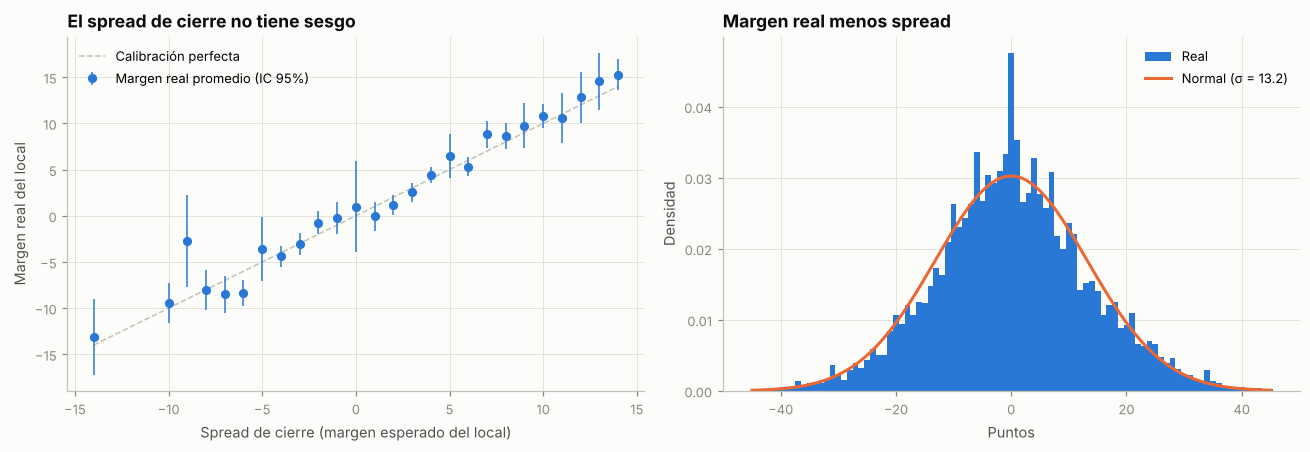

Desviación del residuo: 13.20 puntos | curtosis en exceso: 0.26


In [4]:
SIGMA = g["ats_resid"].std()
b = (g.assign(sb=g["spread_line"].round().clip(-14, 14))
       .groupby("sb")["result"].agg(["mean", "std", "size"]))
b = b[b["size"] >= 30]
se = b["std"] / np.sqrt(b["size"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot([-14, 14], [-14, 14], color=C["base"], lw=1, ls="--", label="Calibración perfecta")
ax.errorbar(b.index, b["mean"], yerr=1.96 * se, fmt="o", color=C["blue"], ms=5, lw=1,
            label="Margen real promedio (IC 95%)")
ax.set(title="El spread de cierre no tiene sesgo", xlabel="Spread de cierre (margen esperado del local)",
       ylabel="Margen real del local")
ax.legend(loc="upper left")

ax = axes[1]
ax.hist(g["ats_resid"], bins=np.arange(-45.5, 46.5, 1), color=C["blue"], density=True, label="Real")
xx = np.linspace(-45, 45, 400)
ax.plot(xx, stats.norm.pdf(xx, 0, SIGMA), color=C["orange"], label=f"Normal (σ = {SIGMA:.1f})")
ax.set(title="Margen real menos spread", xlabel="Puntos", ylabel="Densidad")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Desviación del residuo: {SIGMA:.2f} puntos | curtosis en exceso: {stats.kurtosis(g['ats_resid']):.2f}")

> **Lo que dice la data**
> * La línea de cierre no tiene sesgo: pendiente 1.04 e intercepto prácticamente 0 en 7,356 partidos. No existe un ajuste simple del tipo "los favoritos ganan por más" que deje dinero.
> * El ruido es enorme: una desviación del margen real contra la línea son 13.2 puntos. Incluso el mercado se equivoca por 10 puntos en promedio.
> * El mercado se volvió más preciso: la desviación bajó de 13.5 (1999 a 2014) a 12.5 (2024 a 2026) y el error medio de 10.6 a 9.7 puntos.
> * En 2024 a 2026 la pendiente es 1.17: los favoritos ganaron por más de lo esperado en promedio. Pero el favorito cubre 50.1%, así que es un efecto de unas pocas palizas, no algo apostable.
>
> **Para el modelo:** el objetivo no es acertar ganadores sino bajar el error contra la línea de cierre. Para convertir un spread propio en probabilidad, usa σ entre 12.5 y 13 puntos.

### 2.1 De spread a probabilidad de ganar

Si el residuo es aproximadamente normal con σ ≈ 13, la probabilidad de que el local gane es Φ(spread / σ). Comparo esa fórmula contra lo que pasó en la realidad y contra una logística ajustada. Esta tabla es una herramienta práctica: convierte cualquier spread en probabilidad, y de ahí en moneyline justo.

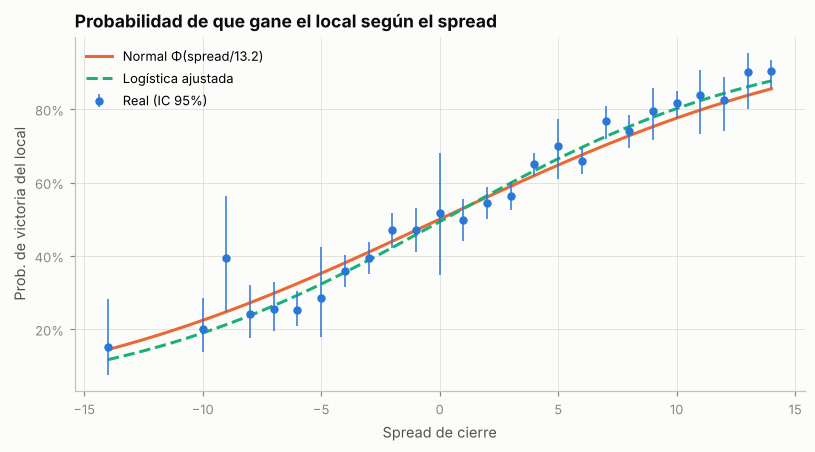

,prob_normal,prob_logistica,moneyline_justo
favorito_por,,,
1.000,0.530,0.529,-112.000
1.500,0.545,0.547,-121.000
2.500,0.575,0.582,-139.000
3.000,0.590,0.599,-149.000
3.500,0.605,0.616,-160.000
4.000,0.619,0.632,-172.000
6.000,0.675,0.696,-229.000
7.000,0.702,0.725,-264.000
7.500,0.715,0.739,-283.000


In [5]:
d = g[(g["result"] != 0)].copy()
logit = sm.Logit((d["result"] > 0).astype(int), sm.add_constant(d["spread_line"])).fit(disp=0)

cal = (g.assign(sb=g["spread_line"].round().clip(-14, 14))
         .groupby("sb")["home_win"].agg(["sum", "size"]))
cal = cal[cal["size"] >= 30]
lo, hi = wilson(cal["sum"], cal["size"])
p_obs = cal["sum"] / cal["size"]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
xx = np.linspace(-14, 14, 200)
ax.plot(xx, stats.norm.cdf(xx / SIGMA), color=C["orange"], label=f"Normal Φ(spread/{SIGMA:.1f})")
ax.plot(xx, logit.predict(sm.add_constant(xx)), color=C["aqua"], ls="--", label="Logística ajustada")
ax.errorbar(cal.index, p_obs, yerr=[p_obs - lo, hi - p_obs], fmt="o", color=C["blue"], ms=4.5, lw=1,
            label="Real (IC 95%)")
ax.set(title="Probabilidad de que gane el local según el spread", xlabel="Spread de cierre",
       ylabel="Prob. de victoria del local")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

lines = np.array([1, 1.5, 2.5, 3, 3.5, 4, 6, 7, 7.5, 9.5, 10, 13.5, 14])
p_fav = logit.predict(sm.add_constant(lines))
tabla_prob = pd.DataFrame({"favorito_por": lines, "prob_normal": stats.norm.cdf(lines / SIGMA),
                           "prob_logistica": p_fav,
                           "moneyline_justo": decimal_to_american(1 / p_fav).round()}).set_index("favorito_por")
tabla_prob

### 2.2 Moneyline: cuánto cobra la casa y el sesgo favorito-longshot

El **hold** es la suma de las probabilidades implícitas menos 1: lo que la casa se queda en promedio. Para obtener la probabilidad "justa" hay que quitarlo (de-vig). Después comparo esa probabilidad contra la frecuencia real de victorias.

El **sesgo favorito-longshot** es un patrón clásico de las casas: los underdogs grandes ganan menos de lo que su precio sugiere, porque el público paga de más por la ilusión de un gran premio. Si existe, apostar longshots pierde más dinero que apostar favoritos.

Hold mediano por periodo: {'2006 a 2022': '2.45%', '2023 a 2026': '4.26%'}


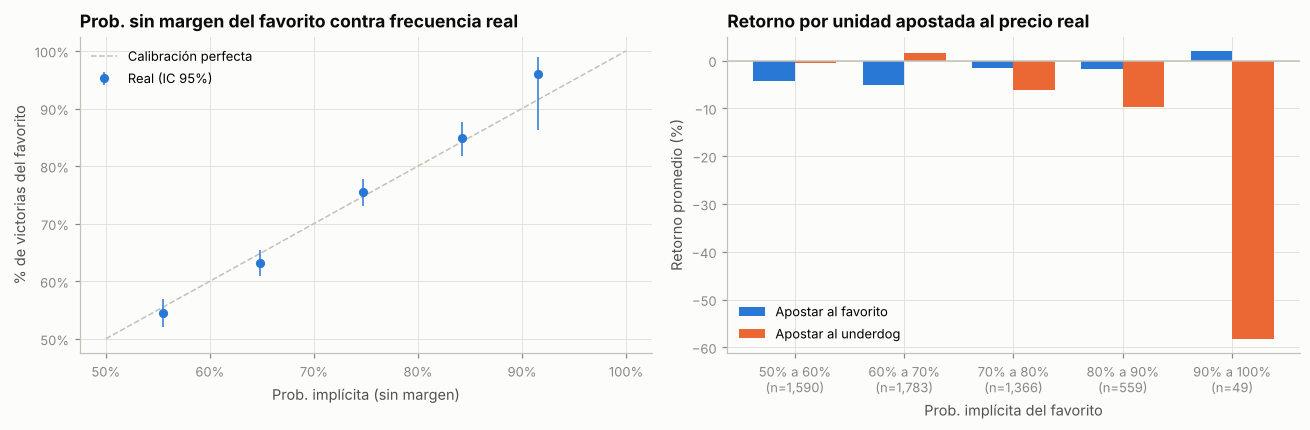

,partidos,prob_mercado,gano_real,roi_favorito,roi_underdog,diferencia_pp
fav_bin,,,,,,
"(0.5, 0.6]",1590,0.555,0.546,-0.044,-0.004,-0.981
"(0.6, 0.7]",1783,0.648,0.632,-0.051,0.015,-1.605
"(0.7, 0.8]",1366,0.747,0.755,-0.016,-0.061,0.753
"(0.8, 0.9]",559,0.842,0.849,-0.019,-0.097,0.696
"(0.9, 1.0]",49,0.916,0.959,0.020,-0.582,4.368


In [6]:
ml = g[g["home_moneyline"].notna() & g["away_moneyline"].notna()].copy()
ml["p_home_raw"] = ml_to_prob(ml["home_moneyline"])
ml["p_away_raw"] = ml_to_prob(ml["away_moneyline"])
ml["hold"] = ml["p_home_raw"] + ml["p_away_raw"] - 1
ml = ml[ml["hold"].between(0, 0.15)]                     # descarta líneas mal cargadas
ml["p_home"] = ml["p_home_raw"] / (ml["p_home_raw"] + ml["p_away_raw"])
ml["fav_p"] = np.maximum(ml["p_home"], 1 - ml["p_home"])
ml["fav_won"] = np.where(ml["p_home"] >= 0.5, ml["home_win"], 1 - ml["home_win"])
# rentabilidad de apostar 1 unidad a cada lado al precio real
dec_h, dec_a = american_to_decimal(ml["home_moneyline"]), american_to_decimal(ml["away_moneyline"])
ml["roi_home"] = np.where(ml["result"] > 0, dec_h - 1, np.where(ml["result"] == 0, 0, -1))
ml["roi_away"] = np.where(ml["result"] < 0, dec_a - 1, np.where(ml["result"] == 0, 0, -1))
ml["roi_fav"] = np.where(ml["p_home"] >= 0.5, ml["roi_home"], ml["roi_away"])
ml["roi_dog"] = np.where(ml["p_home"] >= 0.5, ml["roi_away"], ml["roi_home"])

ml["fuente"] = np.where(ml["season"] >= 2023, "2023 a 2026", "2006 a 2022")
print("Hold mediano por periodo:", ml.groupby("fuente")["hold"].median().map("{:.2%}".format).to_dict())

ml["fav_bin"] = pd.cut(ml["fav_p"], [0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
flb = ml.groupby("fav_bin", observed=True).agg(partidos=("fav_p", "size"), prob_mercado=("fav_p", "mean"),
                                               gano_real=("fav_won", "mean"), roi_favorito=("roi_fav", "mean"),
                                               roi_underdog=("roi_dog", "mean"))
flb["diferencia_pp"] = (flb["gano_real"] - flb["prob_mercado"]) * 100
lo, hi = wilson(flb["gano_real"] * flb["partidos"], flb["partidos"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot([0.5, 1], [0.5, 1], color=C["base"], ls="--", lw=1, label="Calibración perfecta")
ax.errorbar(flb["prob_mercado"], flb["gano_real"], yerr=[flb["gano_real"] - lo, hi - flb["gano_real"]],
            fmt="o", color=C["blue"], ms=5, lw=1, label="Real (IC 95%)")
ax.set(title="Prob. sin margen del favorito contra frecuencia real", xlabel="Prob. implícita (sin margen)",
       ylabel="% de victorias del favorito")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.legend(loc="upper left")
ax = axes[1]
x = np.arange(len(flb))
w = 0.38
ax.bar(x - w / 2, flb["roi_favorito"] * 100, w, color=C["blue"], label="Apostar al favorito")
ax.bar(x + w / 2, flb["roi_underdog"] * 100, w, color=C["orange"], label="Apostar al underdog")
ax.axhline(0, color=C["base"], lw=1)
ax.set_xticks(x, [f"{i.left:.0%} a {i.right:.0%}\n(n={n:,})" for i, n in zip(flb.index, flb["partidos"])])
ax.set(title="Retorno por unidad apostada al precio real", xlabel="Prob. implícita del favorito",
       ylabel="Retorno promedio (%)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
flb

> **Lo que dice la data**
> * Las probabilidades sin margen están bien calibradas: cuando el mercado da 75%, el favorito gana 75.5%.
> * El sesgo favorito-longshot aparece en los extremos. Los underdogs con 10% a 20% de probabilidad devuelven -9.7% por unidad y los de menos de 10%, -58% (solo 49 partidos), contra -1.9% y +2.0% de apostar a sus favoritos. Entre 50% y 70% pasa lo contrario: el favorito es el que pierde más (-4% a -5%).
> * **Ojo con la fuente:** el hold mediano salta de 2.45% (2006 a 2022) a 4.26% (2023 a 2026). Las cuotas viejas tienen precios tipo -104/-104, típicos de una casa sharp, y las nuevas -110/-110, típicos de una casa retail. Es un cambio de fuente en nflverse, no del mercado.
>
> **Para el modelo:** cualquier backtest de rentabilidad tiene que usar los precios de la casa donde de verdad vas a apostar. La diferencia de margen entre una casa sharp y una retail (casi 2 puntos) es más grande que casi cualquier edge.

### 2.3 ¿Hay lados que cubran más que otros?

Si el mercado es eficiente, local, visitante, favorito y underdog deberían cubrir cerca de 50% (sin contar pushes). Cualquier desviación necesita superar 52.4% para ser rentable a -110, y además ser estadísticamente distinta de 50%.

In [7]:
def cover_table(d):
    rows = {}
    nz = d[d["ats_resid"] != 0]
    fav = nz[nz["spread_line"] != 0]
    defs = {
        "Local cubre": nz["ats_resid"] > 0,
        "Favorito cubre": np.where(fav["fav_home"], fav["ats_resid"] > 0, fav["ats_resid"] < 0),
        "Local underdog cubre": nz.loc[nz["spread_line"] < 0, "ats_resid"] > 0,
        "Visitante underdog cubre": nz.loc[nz["spread_line"] > 0, "ats_resid"] < 0,
        "Más del total": d.loc[d["tot_resid"] != 0, "tot_resid"] > 0,
    }
    for name, s in defs.items():
        s = pd.Series(np.asarray(s, bool))
        k, n = s.sum(), len(s)
        lo, hi = wilson(k, n)
        rows[name] = {"n": n, "tasa": k / n, "IC_bajo": lo, "IC_alto": hi,
                      "p_valor_vs_50": stats.binomtest(int(k), n, 0.5).pvalue}
    return pd.DataFrame(rows).T


cover = pd.concat({era: cover_table(d) for era, d in g.groupby("era", observed=True)})
cover

n  tasa  IC_bajo  IC_alto  p_valor_vs_50
1999 a 2014 Local cubre              4,128.000 0.491    0.475    0.506          0.231
            Favorito cubre           4,101.000 0.490    0.474    0.505          0.190
            Local underdog cubre     1,334.000 0.501    0.475    0.528          0.935
            Visitante underdog cubre 2,767.000 0.515    0.496    0.533          0.128
            Más del total            4,170.000 0.499    0.484    0.514          0.889
2015 a 2023 Local cubre              2,388.000 0.485    0.465    0.505          0.146
            Favorito cubre           2,384.000 0.479    0.459    0.499          0.039
            Local underdog cubre       878.000 0.508    0.475    0.541          0.661
            Visitante underdog cubre 1,506.000 0.529    0.504    0.554          0.025
            Más del total            2,433.000 0.479    0.459    0.499          0.039
2024 a 2026 Local cubre                639.000 0.509    0.470    0.547          0.692
            Favorito cubre             639.000 0.501    0.462    0.539          1.000
            Local underdog cubre       261.000 0.510    0.449    0.570          0.805
            Visitante underdog cubre   378.000 0.492    0.442    0.542          0.797
            Más del total              647.000 0.526    0.487    0.564          0.208

> **Lo que dice la data**
> * Ningún lado cubre de forma consistente. Los patrones de una era desaparecen en la siguiente: el underdog visitante cubrió 52.9% en 2015 a 2023 (p = 0.025) y 49.2% en 2024 a 2026; los favoritos cubrieron 47.9% y después 50.1%.
> * Es lo esperable en un mercado eficiente: con 15 comparaciones, alguna sale "significativa" por pura suerte.

## 3. La forma de los resultados: números clave

En la NFL se anota de a 3 (field goal) y de a 7 (touchdown con punto extra). Por eso los márgenes finales se amontonan en 3, 7, 10 y 14. Para una casa de apuestas esto lo es todo: mover una línea de -2.5 a -3 no vale lo mismo que moverla de -5.5 a -6.

Comparo las tres eras para ver si los cambios de reglas movieron esos números.

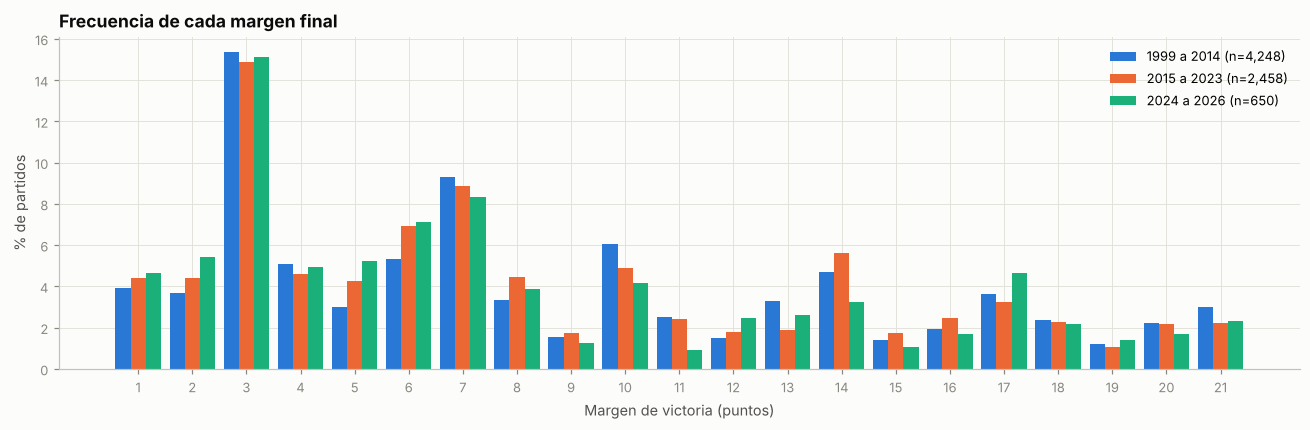

margen,1,2,3,4,6,7,8,10,14
era,,,,,,,,,
1999 a 2014,3.900,3.700,15.300,5.100,5.300,9.300,3.300,6.100,4.700
2015 a 2023,4.400,4.400,14.900,4.600,6.900,8.900,4.500,4.900,5.600
2024 a 2026,4.600,5.400,15.100,4.900,7.100,8.300,3.900,4.200,3.200


In [8]:
g["abs_margin"] = g["result"].abs()
freq = (g[g["abs_margin"] > 0].groupby("era", observed=True)["abs_margin"]
          .value_counts(normalize=True).unstack(0).reindex(range(1, 22)).fillna(0))

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(1, 22)
w = 0.28
colors = [C["blue"], C["orange"], C["aqua"]]
for i, (era, col) in enumerate(zip(freq.columns, colors)):
    n = int((g["era"] == era).sum())
    ax.bar(x + (i - 1) * w, freq[era] * 100, w, color=col, label=f"{era} (n={n:,})")
ax.set_xticks(x)
ax.set(title="Frecuencia de cada margen final", xlabel="Margen de victoria (puntos)", ylabel="% de partidos")
ax.legend()
plt.tight_layout()
plt.show()

key = [1, 2, 3, 4, 6, 7, 8, 10, 14]
(freq.loc[key] * 100).round(1).rename_axis("margen").T

> **Lo que dice la data**
> * El 3 no se mueve: 15% de los partidos en las tres eras.
> * El 7 pierde peso (9.3% a 8.9% a 8.3%) y el 6 lo gana (5.3% a 6.9% a 7.1%). El punto extra más lejano de 2015 trajo más intentos de 2 puntos y más extras fallados, y eso empuja márgenes de 7 hacia 6 y 8.
> * En la era del kickoff dinámico cae el 10 (6.1% a 4.2%) y sube el 2 (3.7% a 5.4%).
>
> **Para el modelo:** la distribución de márgenes no es normal y cambia con las reglas. Para preciar líneas alternativas o teasers hay que usar la distribución de la era reciente, no la de 25 años.

### 3.1 Cuánto vale medio punto

Esta es la hoja de precios que usa un trader para líneas alternativas. Hay dos jugadas típicas:

* **Salir del número:** el cierre es -3 y compras -2.5 (o el underdog compra de +3 a +3.5). La victoria por exactamente 3, que era push, pasa a ser victoria.
* **Llegar al número:** el cierre es -3.5 y compras -3 (o el underdog compra de +2.5 a +3). La derrota por exactamente 3 pasa a ser push.

Para cada caso calculo el precio máximo que vale la pena pagar por la línea comprada, comparado con apostar la línea de cierre a -110. Si la casa cobra menos que ese precio, comprar el medio punto es mejor negocio que apostar el cierre. Uso solo partidos que cerraron exactamente en esa línea (mínimo 80).

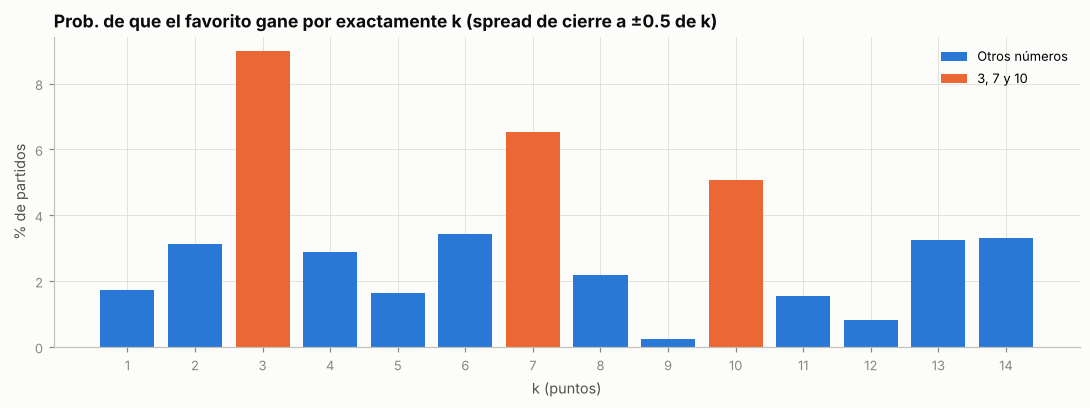

,n_cierre_k,prob_exacto_k,fav_-k_a_-(k-0.5),dog_+k_a_+(k+0.5),fav_-(k+0.5)_a_-k,dog_+(k-0.5)_a_+k
k,,,,,,
1,546.000,0.015,-113.235,-113.308,-116.020,NaN
2,169.000,0.024,-114.944,-115.789,-117.485,-122.737
3,"1,166.000",0.092,-133.307,-131.245,-140.228,-130.853
4,342.000,0.023,-115.116,-115.432,-119.758,-117.378
6,356.000,0.037,-118.462,-118.218,-122.561,-114.827
7,498.000,0.070,-126.595,-126.667,-130.684,-124.183
10,215.000,0.065,-127.111,-123.874,-117.492,-122.703
14,90.000,0.044,-121.579,-119.167,NaN,NaN


In [9]:
def fair_buy(d, k, base=-110):
    """Precio máximo para comprar medio punto alrededor de k, frente a apostar el cierre a -110."""
    dec = float(american_to_decimal(base))
    out = {}

    def price(ev0, loss_after, win_after):
        return float(decimal_to_american(1 + (ev0 + loss_after) / win_after))

    # Cierre exactamente en k: el push pasa a ser victoria
    x = d[d["fav_line"] == k]["fav_margin"]
    if len(x) >= 80:
        w, p, l = (x > k).mean(), (x == k).mean(), (x < k).mean()
        out["n_cierre_k"] = len(x)
        out["prob_exacto_k"] = p
        out[f"fav_-k_a_-(k-0.5)"] = price(w * (dec - 1) - l, l, w + p)
        out[f"dog_+k_a_+(k+0.5)"] = price(l * (dec - 1) - w, w, l + p)
    # Cierre a medio punto del número: la derrota por exactamente k pasa a ser push
    x = d[d["fav_line"] == k + 0.5]["fav_margin"]
    if len(x) >= 80:
        w, l = (x >= k + 1).mean(), (x <= k).mean()
        out["fav_-(k+0.5)_a_-k"] = price(w * (dec - 1) - l, (x < k).mean(), w)
    x = d[d["fav_line"] == k - 0.5]["fav_margin"]
    if len(x) >= 80:
        w, l = (x <= k - 1).mean(), (x >= k).mean()
        out["dog_+(k-0.5)_a_+k"] = price(w * (dec - 1) - l, (x > k).mean(), w)
    return out


fm = g.dropna(subset=["fav_margin"])
exact = pd.Series({k: (fm.loc[fm["fav_line"].between(k - 0.5, k + 0.5), "fav_margin"] == k).mean()
                   for k in range(1, 15)})
fig, ax = plt.subplots(figsize=(10, 3.8))
is_key = exact.index.isin([3, 7, 10])
ax.bar(exact.index[~is_key], exact[~is_key] * 100, color=C["blue"], label="Otros números")
ax.bar(exact.index[is_key], exact[is_key] * 100, color=C["orange"], label="3, 7 y 10")
ax.set_xticks(exact.index)
ax.set(title="Prob. de que el favorito gane por exactamente k (spread de cierre a ±0.5 de k)",
       xlabel="k (puntos)", ylabel="% de partidos")
ax.legend()
plt.tight_layout()
plt.show()

hp = pd.DataFrame({k: fair_buy(fm, k) for k in [1, 2, 3, 4, 6, 7, 10, 14]}).T
hp.index.name = "k"
hp.round(3)

> **Lo que dice la data**
> * Cuando el cierre es -3, el favorito gana por exactamente 3 el 9.2% de las veces. Por eso el medio punto alrededor del 3 vale entre 20 y 30 centavos: comprar de -3 a -2.5 se justifica hasta -133 y de -3.5 a -3 hasta -140.
> * El 7 vale entre 14 y 21 centavos. El 10 y el 14, entre 7 y 17. El 6 y el 4, entre 5 y 13. El 1 y el 2, entre 3 y 13.
> * Comprar medio punto suele costar 10 centavos (de -110 a -120). Solo es buen negocio alrededor de 3, 7 y casi siempre 10; en el resto se paga más de lo que vale.
>
> **Para el modelo:** esta tabla es la base para preciar spreads alternativos y para decidir cuándo comprar puntos.

### 3.2 Teasers: ¿siguen funcionando los Wong teasers?

Un teaser de 6 puntos mueve dos líneas 6 puntos a tu favor a cambio de un pago menor. Stanford Wong mostró que el único teaser rentable es el que cruza el 3 y el 7 a la vez: favoritos de -7.5 a -8.5 (pasan a -1.5 a -2.5) y underdogs de +1.5 a +2.5 (pasan a +7.5 a +8.5).

Para un teaser de 2 equipos, cada pierna tiene que ganar al menos √(1/pago). A -110 son 72.4%, a -120 son 73.9% y a -130 son 75.2%. El mapa de abajo muestra la tasa de acierto de una pierna teaseada para cada línea original.

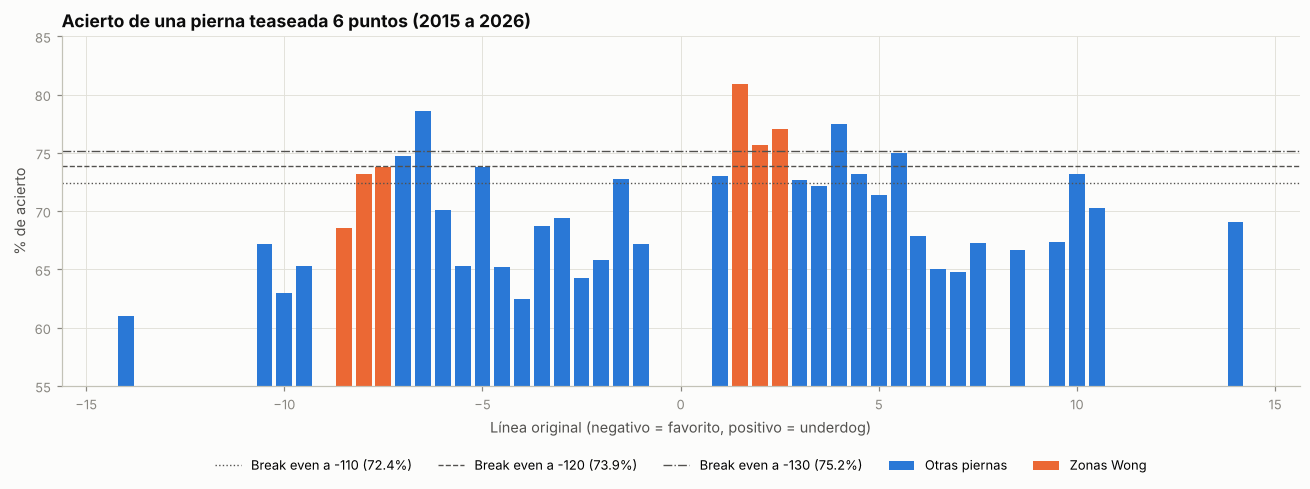

piernas  acierto  IC_bajo  IC_alto
1999 a 2014 Todas                648.000    0.725    0.690    0.758
            Solo visitantes      295.000    0.705    0.651    0.754
            Total de 49 o menos  593.000    0.734    0.697    0.768
2015 a 2023 Todas                575.000    0.767    0.731    0.800
            Solo visitantes      252.000    0.802    0.748    0.846
            Total de 49 o menos  464.000    0.776    0.736    0.811
2024 a 2026 Todas                200.000    0.730    0.665    0.787
            Solo visitantes       97.000    0.753    0.658    0.828
            Total de 49 o menos  176.000    0.739    0.669    0.798

In [10]:
def teaser_leg(d, line, side):
    """Tasa de acierto de una pierna teaseada 6 puntos. side='fav' o 'dog'. Excluye pushes."""
    x = d[(d["fav_line"] == line)].dropna(subset=["fav_margin"])
    m = x["fav_margin"]
    if side == "fav":                      # el favorito pasa de -line a -(line-6)
        new = line - 6
        win, push = m > new, m == new
    else:                                  # el underdog pasa de +line a +(line+6)
        new = line + 6
        win, push = m < new, m == new
    n = int((~push).sum())
    return n, (win & ~push).sum() / max(n, 1)


be = {str(p): np.sqrt(1 / float(american_to_decimal(p))) for p in (-110, -120, -130)}
lines = np.arange(1, 14.5, 0.5)
recent = g[g["season"] >= 2015]
rows = []
for L in lines:
    for side in ("fav", "dog"):
        n, r = teaser_leg(recent, L, side)
        if n >= 40:
            rows.append({"linea": -L if side == "fav" else L, "lado": side, "n": n, "acierto": r})
tmap = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(12, 4.6))
wong = tmap["linea"].abs().between(7.5, 8.5) & (tmap["lado"] == "fav") | tmap["linea"].between(1.5, 2.5) & (tmap["lado"] == "dog")
ax.bar(tmap.loc[~wong, "linea"], tmap.loc[~wong, "acierto"] * 100, width=0.4, color=C["blue"], label="Otras piernas")
ax.bar(tmap.loc[wong, "linea"], tmap.loc[wong, "acierto"] * 100, width=0.4, color=C["orange"], label="Zonas Wong")
for (name, v), ls in zip(be.items(), [":", "--", "-."]):
    ax.axhline(v * 100, color=C["ink2"], lw=0.9, ls=ls, label=f"Break even a {name} ({v:.1%})")
ax.set(title="Acierto de una pierna teaseada 6 puntos (2015 a 2026)",
       xlabel="Línea original (negativo = favorito, positivo = underdog)", ylabel="% de acierto", ylim=(55, 85))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=5)
plt.tight_layout()
plt.show()


def wong_table(d):
    fav = d[d["fav_line"].between(7.5, 8.5)].dropna(subset=["fav_margin"])
    dog = d[d["fav_line"].between(1.5, 2.5)].dropna(subset=["fav_margin"])
    legs = pd.concat([
        pd.DataFrame({"gana": fav["fav_margin"] > fav["fav_line"] - 6, "visitante": ~fav["fav_home"],
                      "total_line": fav["total_line"]}),
        pd.DataFrame({"gana": dog["fav_margin"] < dog["fav_line"] + 6, "visitante": dog["fav_home"],
                      "total_line": dog["total_line"]}),
    ])
    out = {}
    for name, m in {"Todas": legs.index == legs.index, "Solo visitantes": legs["visitante"],
                    "Total de 49 o menos": legs["total_line"] <= 49}.items():
        s = legs.loc[np.asarray(m), "gana"]
        lo, hi = wilson(s.sum(), len(s))
        out[name] = {"piernas": len(s), "acierto": s.mean(), "IC_bajo": lo, "IC_alto": hi}
    return pd.DataFrame(out).T


pd.concat({era: wong_table(d) for era, d in g.groupby("era", observed=True)})

> **Lo que dice la data**
> * Las piernas Wong ganaron 72.5% en 1999 a 2014, 76.7% en 2015 a 2023 y 73.0% en 2024 a 2026 (200 piernas, IC de 66.5% a 78.7%).
> * El break even a -120 es 73.9% y a -130 es 75.2%. La era 2015 a 2023 fue la buena; con el kickoff dinámico el edge desapareció o es demasiado chico para medirlo.
> * Las piernas de underdog rinden más que las de favorito: +1.5 teaseado ganó 81% y -8.5 teaseado solo 69% (2015 a 2026).
> * Filtrar por totales de 49 o menos sube cerca de 1 punto en las tres eras. Jugar solo visitantes sube 2 a 3 puntos desde 2015, pero restaba 2 puntos antes: con estas muestras, no es un filtro confiable.
>
> **Para el modelo:** un teaser solo tiene valor si cruza el 3 y el 7. Si el 7 sigue perdiendo frecuencia, los teasers pierden valor.

### 3.3 Totales y entorno de anotación

El total (over/under) tiene su propia dinámica: depende del entorno de anotación de cada temporada. Si el mercado se queda atrás cuando la liga cambia (más o menos puntos), aparece un sesgo temporal en los overs o unders.

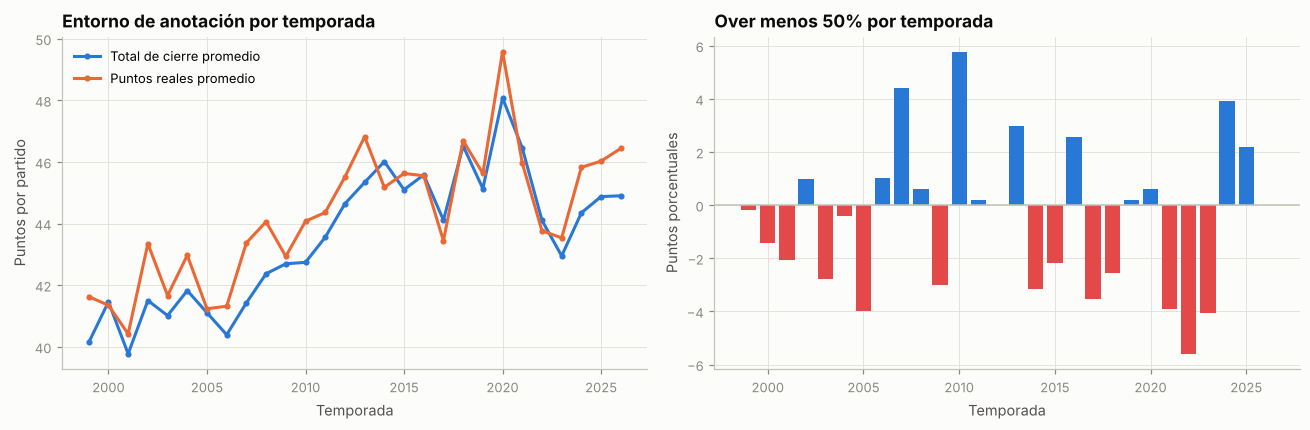

Puntos reales menos total: media +0.71 | mediana +0.00 | over 49.4% | desviación 13.41 | asimetría 0.35


,linea_total,puntos_reales,over
season,,,
2021,46.454,45.963,0.461
2022,44.103,43.764,0.444
2023,42.949,43.537,0.459
2024,44.347,45.824,0.539
2025,44.875,46.026,0.522
2026,44.900,46.438,0.500


In [11]:
tot = g[g["game_type"] == "REG"].groupby("season").agg(
    linea_total=("total_line", "mean"), puntos_reales=("total", "mean"),
    over=("tot_resid", lambda s: (s[s != 0] > 0).mean()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(tot.index, tot["linea_total"], color=C["blue"], marker="o", ms=3, label="Total de cierre promedio")
ax.plot(tot.index, tot["puntos_reales"], color=C["orange"], marker="o", ms=3, label="Puntos reales promedio")
ax.set(title="Entorno de anotación por temporada", xlabel="Temporada", ylabel="Puntos por partido")
ax.legend()
ax = axes[1]
ax.bar(tot.index, (tot["over"] - 0.5) * 100, color=np.where(tot["over"] >= 0.5, C["blue"], C["red"]))
ax.axhline(0, color=C["base"], lw=1)
ax.set(title="Over menos 50% por temporada", xlabel="Temporada", ylabel="Puntos porcentuales")
plt.tight_layout()
plt.show()
r = g["tot_resid"]
print(f"Puntos reales menos total: media {r.mean():+.2f} | mediana {r.median():+.2f} | "
      f"over {(r[r != 0] > 0).mean():.1%} | desviación {r.std():.2f} | asimetría {stats.skew(r):.2f}")
tot.tail(6)

> **Lo que dice la data**
> * En promedio hay 0.7 puntos más que el total, pero el over gana solo 49.4% de las veces. La mediana del residuo es 0: la distribución tiene cola a la derecha por los partidos de muchos puntos. **Para apostar importa el % de acierto, no el promedio.**
> * El mercado de totales se atrasa cuando cambia el entorno. En 2021 a 2023 bajó la anotación y ganaron los unders (44% a 46% de overs). En 2024 y 2025, con el kickoff dinámico, subió la anotación y ganaron los overs (54% y 52%).
>
> **Para el modelo:** al principio de cada temporada, sobre todo si cambian las reglas, el total del mercado puede ir atrasado. Un modelo de totales necesita un componente de entorno de liga que se actualice rápido.

## 4. Ratings implícitos del mercado

Cada spread es una opinión del mercado sobre dos equipos: spread = ventaja de local + rating local − rating visitante. Con todos los spreads de una temporada se pueden resolver los ratings por mínimos cuadrados. Es la forma más limpia de saber qué piensa el mercado de cada equipo, y la base contra la cual se compara cualquier rating propio.

El mismo ajuste da la **ventaja de local que el mercado cobra** cada temporada, y la puedo comparar contra la ventaja de local que realmente ocurrió.

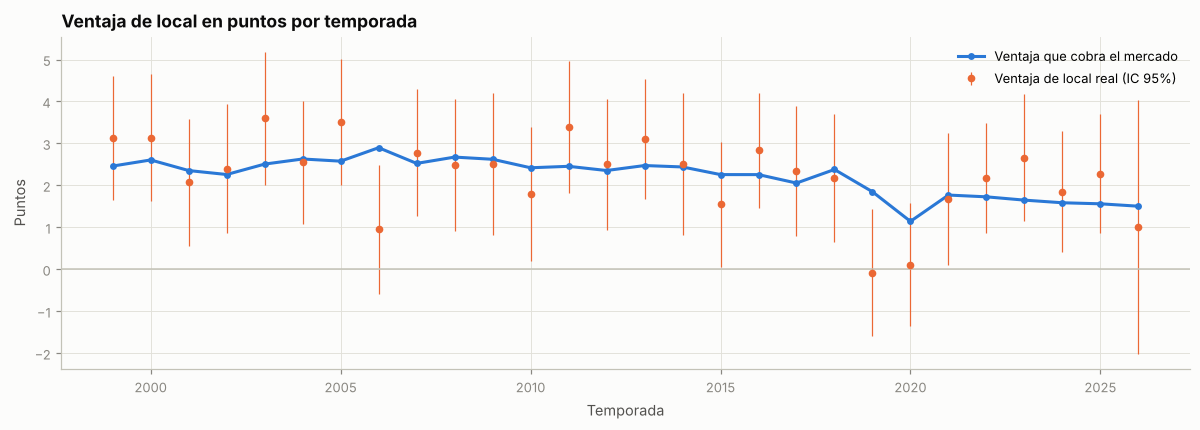

,hfa_mercado,hfa_real,se,partidos
temporada,,,,
2019,1.850,-0.080,0.770,267
2020,1.140,0.110,0.750,269
2021,1.770,1.680,0.800,285
2022,1.730,2.180,0.670,284
2023,1.650,2.660,0.780,285
2024,1.590,1.850,0.740,285
2025,1.560,2.280,0.720,285
2026,1.500,1.010,1.550,80


In [12]:
def market_ratings(d, target="spread_line"):
    """Resuelve target = hfa * local + r_local - r_visitante, con ratings que suman cero."""
    teams = sorted(set(d["home_team"]) | set(d["away_team"]))
    idx = {t: i for i, t in enumerate(teams)}
    X = np.zeros((len(d) + 1, len(teams) + 1))
    for row, (h, a, hf) in enumerate(zip(d["home_team"], d["away_team"], d["home_field"])):
        X[row, idx[h]], X[row, idx[a]], X[row, -1] = 1, -1, hf
    X[-1, :len(teams)] = 1
    y = np.r_[d[target].values, 0]
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return pd.Series(beta[:-1], index=teams), beta[-1]


def realized_hfa(d):
    """Ventaja de local real con su error estándar (mismo diseño, sin restricción)."""
    teams = sorted(set(d["home_team"]) | set(d["away_team"]))
    idx = {t: i for i, t in enumerate(teams)}
    X = np.zeros((len(d), len(teams)))
    for row, (h, a) in enumerate(zip(d["home_team"], d["away_team"])):
        X[row, idx[h]], X[row, idx[a]] = 1, -1
    X = np.c_[X[:, 1:], d["home_field"].values]
    m = sm.OLS(d["result"].values, X).fit()
    return m.params[-1], m.bse[-1]


hfa = []
for s, d in g.groupby("season"):
    _, h_mkt = market_ratings(d)
    h_real, se = realized_hfa(d)
    hfa.append({"temporada": s, "hfa_mercado": h_mkt, "hfa_real": h_real, "se": se, "partidos": len(d)})
hfa = pd.DataFrame(hfa).set_index("temporada")

fig, ax = plt.subplots(figsize=(11, 4))
ax.errorbar(hfa.index, hfa["hfa_real"], yerr=1.96 * hfa["se"], fmt="o", color=C["orange"], ms=4, lw=0.8,
            label="Ventaja de local real (IC 95%)")
ax.plot(hfa.index, hfa["hfa_mercado"], color=C["blue"], marker="o", ms=3.5, label="Ventaja que cobra el mercado")
ax.axhline(0, color=C["base"], lw=1)
ax.set(title="Ventaja de local en puntos por temporada", xlabel="Temporada", ylabel="Puntos")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
hfa.round(2).tail(8)

> **Lo que dice la data**
> * El mercado cobraba unos 2.5 puntos de ventaja de local en los 2000; hoy cobra 1.5.
> * La ventaja real tiene mucho ruido por temporada (IC de ±1.5 puntos). En 2019 y 2020 fue casi cero (2020 sin público).
> * Entre 2021 y 2025 la ventaja real promedió 2.1 puntos contra 1.7 que cobró el mercado. La diferencia no es significativa, pero vale la pena vigilarla.
>
> **Para el modelo:** usa una ventaja de local de 1.5 a 2 puntos, no los 3 puntos clásicos.

### 4.1 Lo que el mercado piensa hoy de cada equipo

Ratings implícitos de la temporada en curso, usando todos los spreads publicados (incluye la próxima semana). Un rating de +5 significa que el mercado cree que ese equipo le ganaría por 5 a un equipo promedio en cancha neutral.

Temporada 2026: 106 spreads usados | ventaja de local implícita: 1.55 puntos


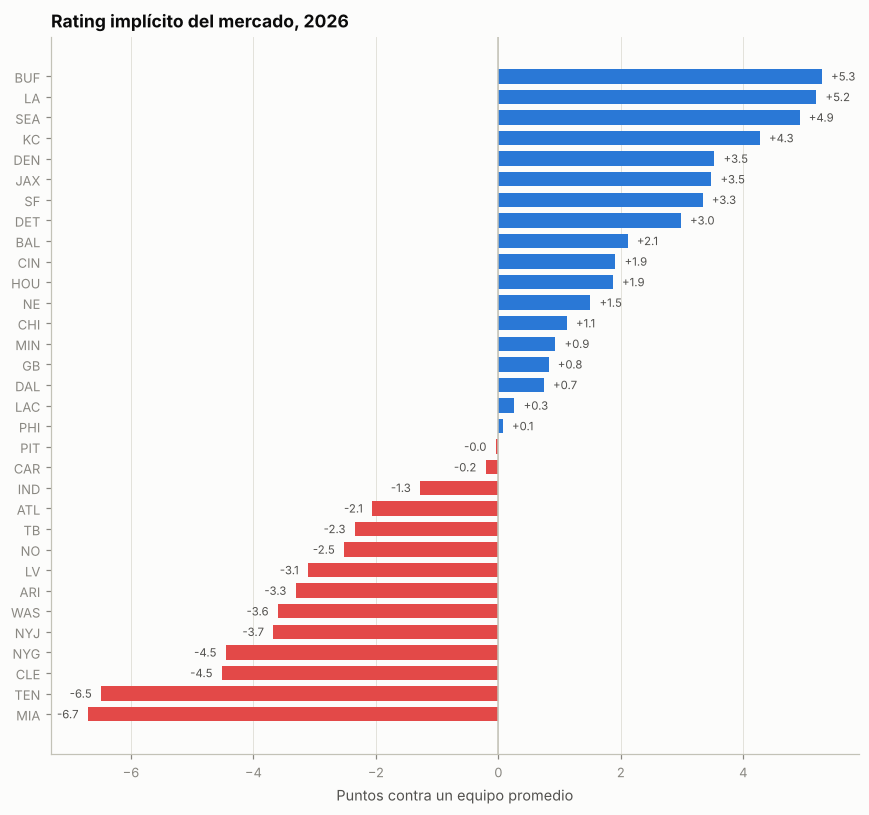

In [13]:
cur = games[(games["season"] == last) & games["spread_line"].notna()].copy()
cur["home_field"] = (cur["location"] == "Home").astype(int)
r_now, h_now = market_ratings(cur)
r_now = r_now.sort_values()
print(f"Temporada {last}: {len(cur)} spreads usados | ventaja de local implícita: {h_now:.2f} puntos")

fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(r_now.index, r_now.values, color=np.where(r_now.values >= 0, C["blue"], C["red"]), height=0.7)
ax.axvline(0, color=C["base"], lw=1)
for t, v in r_now.items():
    ax.text(v + (0.15 if v >= 0 else -0.15), t, f"{v:+.1f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=7.5, color=C["ink2"])
ax.set(title=f"Rating implícito del mercado, {last}", xlabel="Puntos contra un equipo promedio")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 4.2 ¿Cuánto reacciona el mercado a un resultado?

Si un equipo supera la línea por 10 puntos, ¿cuánto sube su rating en el siguiente partido? Ese número es la "tasa de aprendizaje" del mercado, y es justo lo que hay que calibrar en un modelo tipo Elo (el factor K).

También pruebo si esa reacción es correcta: si el mercado sobrerreacciona, el equipo que superó la línea tendería a fallar la siguiente, y la correlación entre residuos consecutivos sería negativa.

In [14]:
rows = []
for s, d in g[g["game_type"] == "REG"].groupby("season"):
    r_season, h_season = market_ratings(d)
    for side in ("home", "away"):
        team = d[f"{side}_team"]
        opp = d["away_team"] if side == "home" else d["home_team"]
        sign = 1 if side == "home" else -1
        rows.append(pd.DataFrame({
            "season": s, "team": team.values, "date": d["gameday"].values,
            "implied": (sign * d["spread_line"] - sign * h_season * d["home_field"] + opp.map(r_season)).values,
            "ats": (sign * d["ats_resid"]).values,
        }))
tl = pd.concat(rows).sort_values(["season", "team", "date"])
tl["next_implied"] = tl.groupby(["season", "team"])["implied"].shift(-1)
tl["next_ats"] = tl.groupby(["season", "team"])["ats"].shift(-1)
tl["delta"] = tl["next_implied"] - tl["implied"]
tl = tl.dropna()

upd = sm.OLS(tl["delta"], sm.add_constant(tl["ats"])).fit(cov_type="HC1")
nxt = sm.OLS(tl["next_ats"], sm.add_constant(tl["ats"])).fit(cov_type="HC1")
print(f"Por cada punto que un equipo supera la línea, su rating implícito sube {upd.params['ats']:.3f} puntos "
      f"(IC 95%: {upd.conf_int().loc['ats', 0]:.3f} a {upd.conf_int().loc['ats', 1]:.3f})")
print(f"Correlación entre el residuo de un partido y el del siguiente: {np.corrcoef(tl['ats'], tl['next_ats'])[0, 1]:+.3f} "
      f"(pendiente {nxt.params['ats']:+.3f}, p = {nxt.pvalues['ats']:.2f})")

bins = pd.cut(tl["ats"], [-60, -21, -14, -7, -3, 3, 7, 14, 21, 60])
resp = tl.groupby(bins, observed=True).agg(n=("delta", "size"), ajuste_rating=("delta", "mean"),
                                           residuo_siguiente=("next_ats", "mean"))
resp

Por cada punto que un equipo supera la línea, su rating implícito sube 0.091 puntos (IC 95%: 0.087 a 0.096)
Correlación entre el residuo de un partido y el del siguiente: -0.007 (pendiente -0.007, p = 0.40)


,n,ajuste_rating,residuo_siguiente
ats,,,
"(-60, -21]",788,-2.204,0.900
"(-21, -14]",1082,-1.524,0.007
"(-14, -7]",1944,-1.148,-0.248
"(-7, -3]",1570,-0.634,0.111
"(-3, 3]",2622,0.014,-0.071
"(3, 7]",1584,0.674,0.128
"(7, 14]",1847,1.185,-0.278
"(14, 21]",1045,1.669,-0.240
"(21, 60]",719,2.170,0.453


> **Lo que dice la data**
> * Por cada punto que un equipo supera la línea, el mercado sube su rating 0.09 puntos para el siguiente partido. Ganarle a la línea por 14 mueve el rating cerca de 1.3 puntos.
> * Esa reacción es correcta en promedio: el residuo del partido siguiente no tiene relación con el anterior (correlación -0.007). El mercado no sobrerreacciona ni se queda corto.
>
> **Para el modelo:** en un Elo o rating de puntos, actualizar alrededor de 9% de la sorpresa por partido replica la velocidad del mercado. Actualizar más rápido es perseguir ruido.

## 5. Señal contra ruido: qué estadísticas predicen el futuro

Esta es la sección más importante para elegir variables. El método es el que usan los equipos de analytics:

1. Para cada equipo y temporada parto los partidos en dos mitades intercaladas (partidos 1, 3, 5... contra 2, 4, 6...).
2. **Estabilidad:** correlación de una estadística consigo misma entre las dos mitades. Si es baja, la estadística es mayormente suerte.
3. **Poder predictivo:** correlación de la estadística en una mitad con el diferencial de puntos en la otra mitad. Esto es lo que importa para modelar.

Uso play by play de 2016 a 2025 (320 temporadas de equipo). EPA por jugada mide cuántos puntos esperados agrega cada jugada según la situación (down, distancia, yarda).

In [15]:
PBP_COLS = ["game_id", "season", "week", "season_type", "posteam", "defteam", "pass", "rush", "epa", "success",
            "yards_gained", "interception", "fumble", "fumble_lost", "down", "third_down_converted",
            "third_down_failed", "drive", "fixed_drive_result", "drive_inside20", "sack", "qb_dropback",
            "penalty", "penalty_team", "penalty_yards"]


def team_game_stats(season):
    p = pd.read_parquet(fetch(PBP_URL.format(season), DATA / f"pbp_{season}.parquet"), columns=PBP_COLS)
    p = p[p["season_type"] == "REG"]
    k = ["game_id", "posteam"]
    pl = p[((p["pass"] == 1) | (p["rush"] == 1)) & p["epa"].notna() & p["posteam"].notna()]
    out = pl.groupby(k).agg(plays=("epa", "size"), epa=("epa", "mean"), success=("success", "mean"),
                            ypp=("yards_gained", "mean"), ints=("interception", "sum"),
                            fumbles=("fumble", "sum"), fum_lost=("fumble_lost", "sum"),
                            sacks=("sack", "sum"), dropbacks=("qb_dropback", "sum"),
                            opp=("defteam", "first"))
    out["pass_epa"] = pl[pl["pass"] == 1].groupby(k)["epa"].mean()
    out["rush_epa"] = pl[pl["rush"] == 1].groupby(k)["epa"].mean()
    third = pl[pl["down"] == 3].groupby(k)[["third_down_converted", "third_down_failed"]].sum()
    out = out.join(third)
    drives = (p[p["posteam"].notna() & p["drive"].notna()]
              .assign(td=lambda x: x["fixed_drive_result"].eq("Touchdown"))
              .groupby(k + ["drive"]).agg(rz=("drive_inside20", "max"), td=("td", "max")))
    drives["rz_td"] = (drives["rz"] == 1) & drives["td"]
    out = out.join(drives.groupby(level=[0, 1]).agg(rz_drives=("rz", "sum"), rz_tds=("rz_td", "sum")))
    pen = p[p["penalty"] == 1].groupby(["game_id", "penalty_team"])["penalty_yards"].sum()
    pen.index.names = k
    out["pen_yards"] = pen
    out = out.fillna({"pen_yards": 0}).reset_index().rename(columns={"posteam": "team"})
    allowed = out.drop(columns=["opp"]).add_prefix("opp_").rename(columns={"opp_game_id": "game_id"})
    tg = out.merge(allowed, left_on=["game_id", "opp"], right_on=["game_id", "opp_team"]).drop(columns="opp_team")
    return tg


cache = DATA / "team_games_pbp.csv"
if cache.exists():
    tg = pd.read_csv(cache)
else:
    tg = pd.concat([team_game_stats(s) for s in PBP_SEASONS], ignore_index=True)
    tg.to_csv(cache, index=False)

score = pd.concat([
    games[["game_id", "season", "week", "home_team", "home_score", "away_score"]]
        .rename(columns={"home_team": "team", "home_score": "pf", "away_score": "pa"}),
    games[["game_id", "season", "week", "away_team", "away_score", "home_score"]]
        .rename(columns={"away_team": "team", "away_score": "pf", "home_score": "pa"}),
])
score["team"] = score["team"].replace({"SD": "LAC", "OAK": "LV", "STL": "LA"})   # play by play usa códigos actuales
tg = tg.merge(score, on=["game_id", "team"], how="left")
tg = tg.dropna(subset=["season"]).astype({"season": int, "week": int})
print(f"{len(tg):,} partidos de equipo | temporadas {tg['season'].min()} a {tg['season'].max()}")
tg[["game_id", "team", "opp", "plays", "epa", "success", "pass_epa", "rush_epa", "opp_epa", "pf", "pa"]].head(4)

5,278 partidos de equipo | temporadas 2016 a 2025


,game_id,team,opp,plays,epa,success,pass_epa,rush_epa,opp_epa,pf,pa
0,2016_01_BUF_BAL,BAL,BUF,65,-0.079,0.400,0.149,-0.422,-0.165,13.000,7.000
1,2016_01_BUF_BAL,BUF,BAL,49,-0.165,0.347,-0.068,-0.294,-0.079,7.000,13.000
2,2016_01_CAR_DEN,CAR,DEN,69,0.042,0.420,0.030,0.057,0.027,20.000,21.000
3,2016_01_CAR_DEN,DEN,CAR,56,0.027,0.500,0.009,0.051,0.042,21.000,20.000


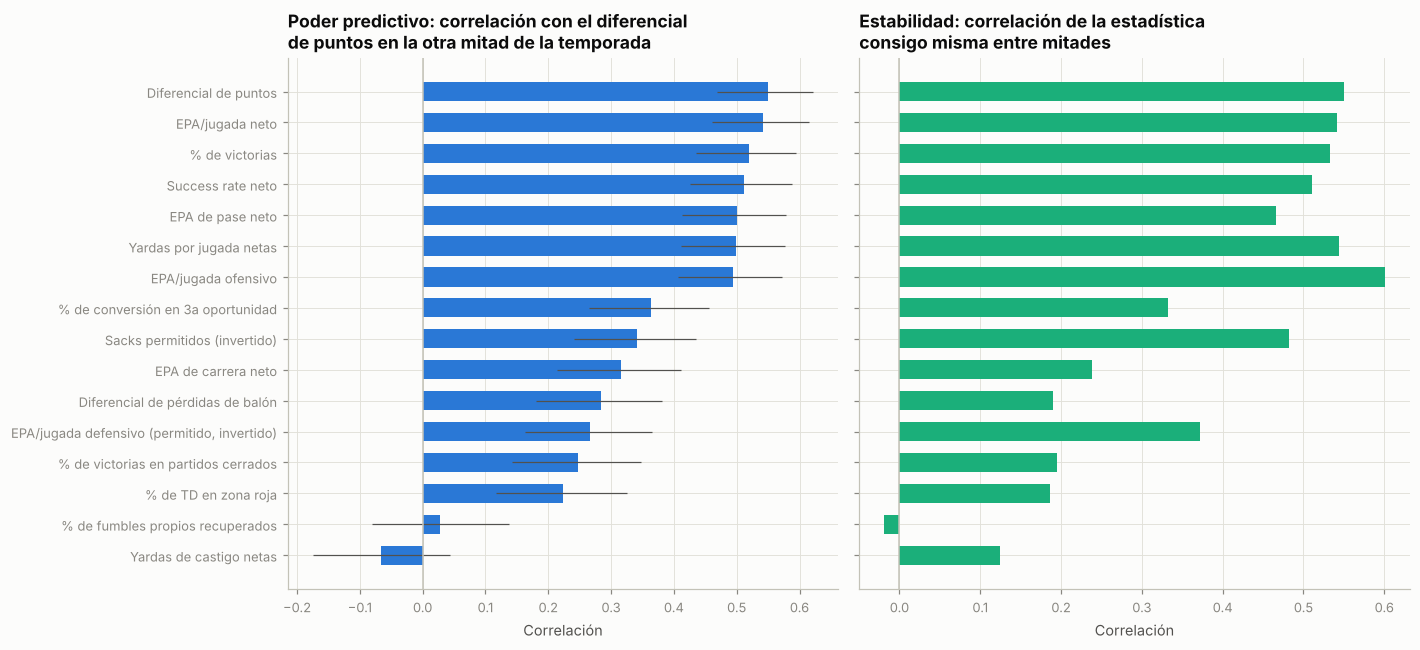

Promedio de diferencial de puntos y EPA neto (estandarizados): correlación predictiva 0.552


,estabilidad,predictivo,pred_bajo,pred_alto,n
estadistica,,,,,
Diferencial de puntos,0.550,0.550,0.468,0.622,320
EPA/jugada neto,0.542,0.543,0.460,0.616,320
% de victorias,0.533,0.519,0.435,0.595,320
Success rate neto,0.510,0.511,0.425,0.588,320
EPA de pase neto,0.466,0.500,0.413,0.578,320
Yardas por jugada netas,0.544,0.499,0.411,0.577,320
EPA/jugada ofensivo,0.600,0.494,0.406,0.572,320
% de conversión en 3a oportunidad,0.333,0.364,0.265,0.455,320
Sacks permitidos (invertido),0.482,0.341,0.241,0.435,320


In [16]:
x = tg.copy()
x["pd"] = x["pf"] - x["pa"]
x["win"] = np.where(x["pd"] > 0, 1, np.where(x["pd"] == 0, 0.5, 0))
x["close"] = x["pd"].abs() <= 8
x["close_win"] = np.where(x["close"], x["win"], np.nan)
x["to_margin"] = (x["opp_ints"] + x["opp_fum_lost"]) - (x["ints"] + x["fum_lost"])
x["order"] = x.groupby(["season", "team"])["week"].rank(method="first")
x["half"] = np.where(x["order"] % 2 == 1, "A", "B")

agg = x.groupby(["season", "team", "half"]).agg(
    games=("pd", "size"), pd=("pd", "mean"), win=("win", "mean"), close_win=("close_win", "mean"),
    epa=("epa", "mean"), opp_epa=("opp_epa", "mean"), pass_epa=("pass_epa", "mean"),
    opp_pass_epa=("opp_pass_epa", "mean"), rush_epa=("rush_epa", "mean"), opp_rush_epa=("opp_rush_epa", "mean"),
    success=("success", "mean"), opp_success=("opp_success", "mean"), ypp=("ypp", "mean"), opp_ypp=("opp_ypp", "mean"),
    to_margin=("to_margin", "mean"), fumbles=("fumbles", "sum"), fum_lost=("fum_lost", "sum"),
    conv=("third_down_converted", "sum"), fail=("third_down_failed", "sum"),
    rz_drives=("rz_drives", "sum"), rz_tds=("rz_tds", "sum"), sacks=("sacks", "sum"), dropbacks=("dropbacks", "sum"),
    pen=("pen_yards", "mean"), opp_pen=("opp_pen_yards", "mean"))

metrics = pd.DataFrame({
    "Diferencial de puntos": agg["pd"],
    "% de victorias": agg["win"],
    "% de victorias en partidos cerrados": agg["close_win"],
    "EPA/jugada neto": agg["epa"] - agg["opp_epa"],
    "EPA/jugada ofensivo": agg["epa"],
    "EPA/jugada defensivo (permitido, invertido)": -agg["opp_epa"],
    "EPA de pase neto": agg["pass_epa"] - agg["opp_pass_epa"],
    "EPA de carrera neto": agg["rush_epa"] - agg["opp_rush_epa"],
    "Success rate neto": agg["success"] - agg["opp_success"],
    "Yardas por jugada netas": agg["ypp"] - agg["opp_ypp"],
    "Diferencial de pérdidas de balón": agg["to_margin"],
    "% de fumbles propios recuperados": 1 - agg["fum_lost"] / agg["fumbles"].replace(0, np.nan),
    "% de conversión en 3a oportunidad": agg["conv"] / (agg["conv"] + agg["fail"]),
    "% de TD en zona roja": agg["rz_tds"] / agg["rz_drives"].replace(0, np.nan),
    "Sacks permitidos (invertido)": -agg["sacks"] / agg["dropbacks"],
    "Yardas de castigo netas": agg["opp_pen"] - agg["pen"],
})
A = metrics.xs("A", level="half")
B = metrics.xs("B", level="half")
A, B = A.align(B, join="inner", axis=0)


def corr_ci(a, b):
    ok = a.notna() & b.notna()
    r = np.corrcoef(a[ok], b[ok])[0, 1]
    n = ok.sum()
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return r, np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se), n


sig = []
for col in metrics.columns:
    rel = corr_ci(A[col], B[col])
    p1 = corr_ci(A[col], B["Diferencial de puntos"])
    p2 = corr_ci(B[col], A["Diferencial de puntos"])
    sig.append({"estadistica": col, "estabilidad": rel[0], "predictivo": (p1[0] + p2[0]) / 2,
                "pred_bajo": (p1[1] + p2[1]) / 2, "pred_alto": (p1[2] + p2[2]) / 2, "n": rel[3]})
sig = pd.DataFrame(sig).set_index("estadistica").sort_values("predictivo")

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
y = np.arange(len(sig))
ax = axes[0]
ax.barh(y, sig["predictivo"], color=C["blue"], height=0.62)
ax.errorbar(sig["predictivo"], y, xerr=[sig["predictivo"] - sig["pred_bajo"], sig["pred_alto"] - sig["predictivo"]],
            fmt="none", ecolor=C["ink2"], lw=0.8)
ax.set_yticks(y, sig.index)
ax.axvline(0, color=C["base"], lw=1)
ax.set(title="Poder predictivo: correlación con el diferencial\nde puntos en la otra mitad de la temporada",
       xlabel="Correlación")
ax = axes[1]
ax.barh(y, sig["estabilidad"], color=C["aqua"], height=0.62)
ax.axvline(0, color=C["base"], lw=1)
ax.set(title="Estabilidad: correlación de la estadística\nconsigo misma entre mitades", xlabel="Correlación")
plt.tight_layout()
plt.show()
z = lambda s: (s - s.mean()) / s.std()
combo_A = (z(A["Diferencial de puntos"]) + z(A["EPA/jugada neto"])) / 2
combo_B = (z(B["Diferencial de puntos"]) + z(B["EPA/jugada neto"])) / 2
r_combo = (np.corrcoef(combo_A, B["Diferencial de puntos"])[0, 1] + np.corrcoef(combo_B, A["Diferencial de puntos"])[0, 1]) / 2
print(f"Promedio de diferencial de puntos y EPA neto (estandarizados): correlación predictiva {r_combo:.3f}")
sig.sort_values("predictivo", ascending=False).round(3)

> **Lo que dice la data**
> * Lo que mejor predice: diferencial de puntos (0.55), EPA por jugada neto (0.54), success rate (0.51) y EPA de pase (0.50). Combinar diferencial de puntos y EPA casi no agrega (0.552).
> * El pase pesa mucho más que la carrera: 0.50 contra 0.32, y la carrera es poco estable (0.24).
> * La ofensiva es más estable (0.60) que la defensa (0.37).
> * Casi pura suerte: % de fumbles propios recuperados (estabilidad -0.02), yardas de castigo, % de victorias en partidos cerrados (0.20) y diferencial de pérdidas de balón (0.19).
>
> **Para el modelo:** usa EPA por jugada, con más peso al pase y a la ofensiva, junto al diferencial de puntos. Regresa fuerte hacia la media las pérdidas de balón y el récord en partidos cerrados: un equipo 6-1 en partidos cerrados no es tan bueno como su récord.

### 5.1 ¿El mercado ya incorpora el EPA?

Que el EPA prediga el futuro no basta: la pregunta de una casa de apuestas es si la línea de cierre ya lo tiene en cuenta. Para cada partido calculo el EPA neto y el diferencial de puntos de cada equipo con los partidos previos de esa temporada (solo información disponible antes del partido) y pruebo si explican el residuo contra el spread.

Si los coeficientes son cero, el mercado ya lo descuenta y un modelo basado solo en EPA no va a ganarle a la línea de cierre.

In [17]:
y_ = x.sort_values(["season", "team", "week"]).copy()
y_["net_epa"] = y_["epa"] - y_["opp_epa"]
grp = y_.groupby(["season", "team"])
y_["pre_epa"] = grp["net_epa"].transform(lambda s: s.shift().expanding().mean())
y_["pre_pd"] = grp["pd"].transform(lambda s: s.shift().expanding().mean())
y_["prev_games"] = grp.cumcount()

feat = y_[["game_id", "team", "pre_epa", "pre_pd", "prev_games"]]
CODES = {"SD": "LAC", "OAK": "LV", "STL": "LA"}
g_pbp = g[g["game_type"] == "REG"].assign(home_team=lambda d: d["home_team"].replace(CODES),
                                          away_team=lambda d: d["away_team"].replace(CODES))
m = (g_pbp.merge(feat.add_prefix("h_"), left_on=["game_id", "home_team"], right_on=["h_game_id", "h_team"])
       .merge(feat.add_prefix("a_"), left_on=["game_id", "away_team"], right_on=["a_game_id", "a_team"]))
m = m[(m["h_prev_games"] >= 3) & (m["a_prev_games"] >= 3)].copy()
m["diff_epa"] = m["h_pre_epa"] - m["a_pre_epa"]
m["diff_pd"] = m["h_pre_pd"] - m["a_pre_pd"]

print(f"Partidos: {len(m):,} | correlación entre las dos variables: {m[['diff_epa', 'diff_pd']].corr().iloc[0, 1]:.2f}")
for cols in (["diff_epa"], ["diff_pd"], ["diff_epa", "diff_pd"]):
    o = sm.OLS(m["ats_resid"], sm.add_constant(m[cols])).fit(cov_type="HC1")
    print(f"  residuo ATS ~ {' + '.join(cols):20s} | " +
          " | ".join(f"{c}: {o.params[c]:+.3f} (p = {o.pvalues[c]:.3f})" for c in cols) + f" | R2 = {o.rsquared:.4f}")

train, test = m[m["season"] <= 2021], m[m["season"] >= 2022]
base = sm.OLS(train["result"], sm.add_constant(train[["spread_line"]])).fit()
full = sm.OLS(train["result"], sm.add_constant(train[["spread_line", "diff_epa", "diff_pd"]])).fit()
pred_base = base.predict(sm.add_constant(test[["spread_line"]]))
pred_full = full.predict(sm.add_constant(test[["spread_line", "diff_epa", "diff_pd"]]))
mae = {"Solo spread": (test["result"] - pred_base).abs().mean(),
       "Spread + EPA + dif. puntos": (test["result"] - pred_full).abs().mean()}
edge = pred_full - test["spread_line"]
pick_home = edge > 0
won = np.where(pick_home, test["ats_resid"] > 0, test["ats_resid"] < 0)
valid = (test["ats_resid"] != 0) & (edge.abs() >= 1.5)
print(f"\nFuera de muestra 2022 a 2025 (MAE): " + " | ".join(f"{k}: {v:.3f}" for k, v in mae.items()))
print(f"Apuestas donde el modelo difiere 1.5+ puntos de la línea: {valid.sum()} | acierto: {won[valid].mean():.1%}")

Partidos: 2,158 | correlación entre las dos variables: 0.96
  residuo ATS ~ diff_epa             | diff_epa: +0.960 (p = 0.532) | R2 = 0.0002
  residuo ATS ~ diff_pd              | diff_pd: +0.034 (p = 0.253) | R2 = 0.0006
  residuo ATS ~ diff_epa + diff_pd   | diff_epa: -8.388 (p = 0.103) | diff_pd: +0.191 (p = 0.054) | R2 = 0.0018

Fuera de muestra 2022 a 2025 (MAE): Solo spread: 9.449 | Spread + EPA + dif. puntos: 9.455
Apuestas donde el modelo difiere 1.5+ puntos de la línea: 12 | acierto: 58.3%


> **Lo que dice la data**
> * Ni el EPA ni el diferencial de puntos acumulados explican el residuo contra la línea de cierre (p = 0.53 y p = 0.25, R² menor a 0.001). Entre ellos tienen correlación 0.96, por eso en la regresión conjunta los coeficientes cambian de signo y no son confiables.
> * Fuera de muestra (2022 a 2025), agregarlos al spread no baja el error: 9.455 contra 9.449.
>
> **Para el modelo:** la línea de cierre ya incorpora las estadísticas públicas. Un modelo hecho solo con ellas puede igualar al mercado, pero no ganarle. Si hay edge, está en información que llega tarde (lesiones, clima, cambios de QB), en las líneas de apertura o en mercados menos líquidos como props.

## 6. Factores situacionales: tendencias reales o ruido

Las "tendencias" son el producto estrella de los tipsters: "los underdogs divisionales cubren 55%". Pruebo 15 factores clásicos contra el residuo del mercado (spread o total). Para cada uno muestro el efecto, su intervalo de confianza y el p-valor, y después aplico la corrección de Benjamini-Hochberg, porque al probar muchas hipótesis algunas salen "significativas" por pura suerte.

Un factor solo vale para el modelo si: (1) sobrevive la corrección, (2) tiene el mismo signo en las dos mitades de la historia y (3) tiene una explicación causal.

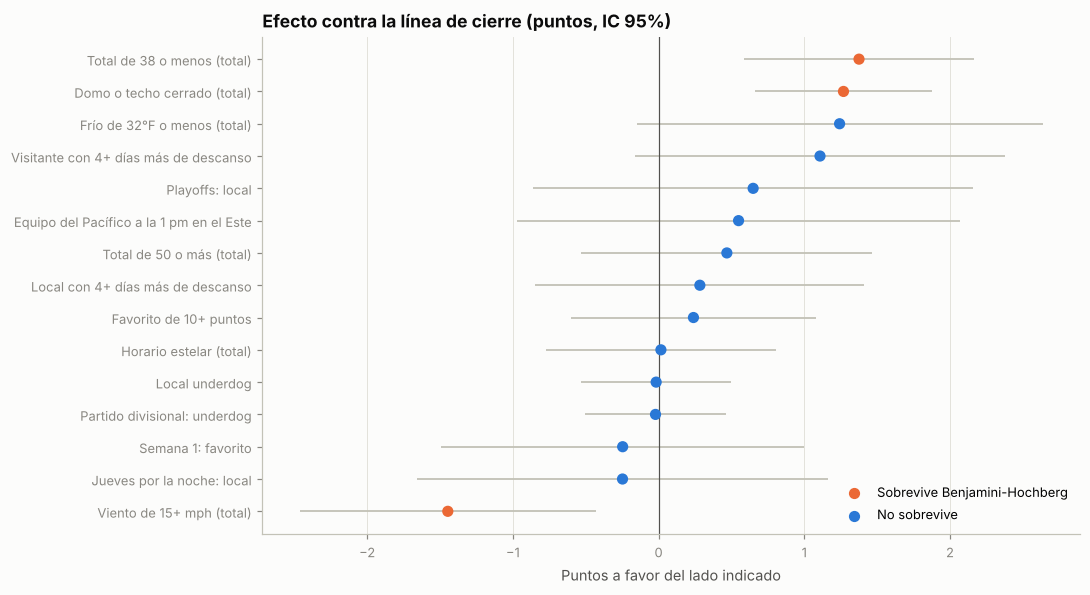

Con 15 pruebas al 5%, la probabilidad de al menos un falso positivo es 54%.


,n,efecto_pts,IC_bajo,IC_alto,%_positivo,p_valor,1999_2012,2013_2026,umbral_BH,sobrevive_BH,mismo_signo
factor,,,,,,,,,,,
Local con 4+ días más de descanso,489,0.283,-0.845,1.411,0.485,0.623,0.791,-0.333,0.033,False,False
Visitante con 4+ días más de descanso,385,1.108,-0.165,2.381,0.533,0.089,1.879,0.387,0.017,False,True
Jueves por la noche: local,311,-0.248,-1.658,1.163,0.507,0.731,-0.362,-0.203,0.040,False,True
Partido divisional: underdog,2748,-0.021,-0.504,0.461,0.522,0.932,-0.086,0.052,0.043,False,False
Local underdog,2487,-0.017,-0.533,0.499,0.505,0.949,-0.090,0.050,0.047,False,False
Favorito de 10+ puntos,907,0.239,-0.604,1.083,0.480,0.578,0.228,0.252,0.030,False,True
Playoffs: local,309,0.649,-0.861,2.158,0.508,0.400,0.373,0.923,0.023,False,True
Semana 1: favorito,440,-0.247,-1.492,0.999,0.478,0.698,0.419,-0.895,0.037,False,False
Equipo del Pacífico a la 1 pm en el Este,297,0.549,-0.969,2.067,0.510,0.479,-0.818,1.642,0.027,False,False


In [18]:
PACIFIC = {"SEA", "SF", "LA", "LAC", "LV", "OAK", "SD"}
EASTERN = {"BUF", "MIA", "NE", "NYJ", "NYG", "PHI", "WAS", "BAL", "PIT", "CLE", "CIN", "DET", "IND",
           "ATL", "CAR", "TB", "JAX"}
s = g.copy()
s["rest_diff"] = s["home_rest"] - s["away_rest"]
s["dog_resid"] = -(s["fav_margin"] - s["fav_line"])              # residuo desde el underdog
s["fav_resid"] = s["fav_margin"] - s["fav_line"]
outdoor = s["roof"].isin(["outdoors", "open"])
reg = s["game_type"] == "REG"

tests = [  # nombre, máscara, columna, signo (1 = como está, -1 = invertido)
    ("Local con 4+ días más de descanso", s["rest_diff"] >= 4, "ats_resid", 1),
    ("Visitante con 4+ días más de descanso", s["rest_diff"] <= -4, "ats_resid", -1),
    ("Jueves por la noche: local", reg & (s["weekday"] == "Thursday") & (s["week"] > 1), "ats_resid", 1),
    ("Partido divisional: underdog", s["div_game"] == 1, "dog_resid", 1),
    ("Local underdog", (s["spread_line"] < 0) & (s["home_field"] == 1), "ats_resid", 1),
    ("Favorito de 10+ puntos", s["fav_line"] >= 10, "fav_resid", 1),
    ("Playoffs: local", s["game_type"] != "REG", "ats_resid", 1),
    ("Semana 1: favorito", reg & (s["week"] == 1), "fav_resid", 1),
    ("Equipo del Pacífico a la 1 pm en el Este",
     s["away_team"].isin(PACIFIC) & s["home_team"].isin(EASTERN) & (s["gametime"].fillna("99:99") < "14:00"), "ats_resid", -1),
    ("Viento de 15+ mph (total)", outdoor & (s["wind"] >= 15), "tot_resid", 1),
    ("Frío de 32°F o menos (total)", outdoor & (s["temp"] <= 32), "tot_resid", 1),
    ("Horario estelar (total)", s["gametime"].fillna("00:00") >= "20:00", "tot_resid", 1),
    ("Domo o techo cerrado (total)", s["roof"].isin(["dome", "closed"]), "tot_resid", 1),
    ("Total de 50 o más (total)", s["total_line"] >= 50, "tot_resid", 1),
    ("Total de 38 o menos (total)", s["total_line"] <= 38, "tot_resid", 1),
]

rows = []
for name, mask, col, sign in tests:
    v = sign * s.loc[mask, col].dropna()
    early = sign * s.loc[mask & (s["season"] <= 2012), col].dropna()
    late = sign * s.loc[mask & (s["season"] > 2012), col].dropna()
    t = stats.ttest_1samp(v, 0)
    nz = v[v != 0]
    rows.append({"factor": name, "n": len(v), "efecto_pts": v.mean(),
                 "IC_bajo": v.mean() - 1.96 * v.std() / np.sqrt(len(v)),
                 "IC_alto": v.mean() + 1.96 * v.std() / np.sqrt(len(v)),
                 "%_positivo": (nz > 0).mean(), "p_valor": t.pvalue,
                 "1999_2012": early.mean(), "2013_2026": late.mean()})
sit = pd.DataFrame(rows).set_index("factor")

# Benjamini-Hochberg: ordena p-valores y compara cada uno con (rango / pruebas) x 5%
m_tests = len(sit)
sit["umbral_BH"] = sit["p_valor"].rank(method="first") / m_tests * 0.05
srt = sit.sort_values("p_valor")
below = (srt["p_valor"] <= srt["umbral_BH"]).values
cut = srt["p_valor"].values[below.nonzero()[0].max()] if below.any() else -1
sit["sobrevive_BH"] = sit["p_valor"] <= cut
sit["mismo_signo"] = np.sign(sit["1999_2012"]) == np.sign(sit["2013_2026"])

fig, ax = plt.subplots(figsize=(10, 5.5))
p = sit.sort_values("efecto_pts")
yy = np.arange(len(p))
col = np.where(p["sobrevive_BH"], C["orange"], C["blue"])
ax.errorbar(p["efecto_pts"], yy, xerr=[p["efecto_pts"] - p["IC_bajo"], p["IC_alto"] - p["efecto_pts"]],
            fmt="none", ecolor=C["base"], lw=1.2)
ax.scatter(p["efecto_pts"], yy, c=col, s=40, zorder=3)
ax.axvline(0, color=C["ink2"], lw=0.8)
ax.set_yticks(yy, p.index)
ax.set(title="Efecto contra la línea de cierre (puntos, IC 95%)", xlabel="Puntos a favor del lado indicado")
ax.scatter([], [], c=C["orange"], s=40, label="Sobrevive Benjamini-Hochberg")
ax.scatter([], [], c=C["blue"], s=40, label="No sobrevive")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

p_any = 1 - 0.95 ** m_tests
print(f"Con {m_tests} pruebas al 5%, la probabilidad de al menos un falso positivo es {p_any:.0%}.")
sit.round(3)

> **Lo que dice la data**
> * De 15 factores, 3 sobreviven la corrección por pruebas múltiples y solo uno pasa los tres filtros:
>   * **Viento de 15+ mph:** 1.4 puntos menos de lo que dice el total, con el mismo signo en las dos mitades de la historia (-1.4 y -1.5). El under ganó 57% de 684 partidos.
>   * **Domo o techo cerrado:** 1.3 puntos más en promedio, pero el over gana solo 51.5%. El efecto viene de pocos partidos con muchos puntos y no alcanza el 52.4% necesario.
>   * **Totales de 38 o menos:** el efecto cambia de signo entre eras (+1.7 y -0.7). Es ruido.
> * Los clásicos de los tipsters (underdog divisional, local underdog, jueves por la noche, semana 1) no tienen efecto contra la línea.
>
> **Para el modelo:** el viento es la única variable situacional que vale la pena probar, y con cuidado: aquí uso el viento real del partido, y al apostar solo tienes el pronóstico.

## 7. Insights y plan de modelado

### Lo más importante

1. **La línea de cierre es casi imposible de vencer con estadísticas públicas.** No tiene sesgo, se actualiza a la velocidad correcta y ya incorpora EPA y diferencial de puntos.
2. **La forma de los resultados vale dinero.** Los números clave (3, 7, 10, 6) definen el precio de cada medio punto, y están cambiando con las reglas. Con eso se precian líneas alternativas, teasers y props, que es justo el trabajo de una casa de apuestas.
3. **Hay pocas señales y mucho ruido.** EPA de pase, success rate y diferencial de puntos predicen; pérdidas de balón, fumbles, partidos cerrados y penalidades son mayormente suerte.
4. **Los edges que existen son chicos y temporales:** viento en totales, totales atrasados cuando cambia el entorno de anotación y los Wong teasers en su mejor época.

### Plan de modelado

| Paso | Qué hacer | Cómo se mide |
|---|---|---|
| 1. Ratings | Rating por equipo con diferencial de puntos y EPA (más peso al pase y a la ofensiva), ventaja de local de 1.5 a 2 puntos y actualización de ~9% de la sorpresa por partido | Error medio contra el resultado, comparado con la línea de cierre |
| 2. Distribución | Convertir el spread del modelo en una distribución de márgenes con los números clave de la era reciente | Calibración de pushes y de líneas alternativas |
| 3. Totales | Modelo de puntos con un entorno de liga que se actualiza rápido y un ajuste por viento | % de acierto contra el total de cierre |
| 4. Validación | Walk forward por temporada: entrenar con el pasado y probar en la siguiente | Closing line value (CLV): si tu número le gana al cierre de forma consistente, el modelo sirve |
| 5. Datos nuevos | Cruzar con ESPN (lesiones, cuotas de apertura) usando la columna `espn` de nflverse | Si el edge aparece en la apertura y desaparece en el cierre, es real |

**Mi opinión honesta:** como apostador, la NFL es el mercado más eficiente que hay. Si el objetivo es un negocio, tiene más sentido usar estos modelos como los usa una casa de apuestas (preciar props y líneas alternativas, o vender proyecciones) que intentar ganarle a la línea de cierre.